# Customer Satisfaction & Complaint Analysis Dashboard

**Skills shown:** complaint handling through to closure, spotting recurring causes, structured feedback for root-cause analysis, customer satisfaction (CSAT) analysis.

This notebook analyses customer complaints by **category**, **channel** and **resolution time** to answer three questions:

1. Which issues come up most often?
2. Where do customers wait longest for a resolution?
3. How does waiting time affect satisfaction and repeat contacts?

> **About the data:** the complaints below are **simulated** (fixed random seed), because real customer data cannot be shared. The simulation includes realistic patterns (for example, longer waits lowering CSAT) so the analysis can be demonstrated. The numbers illustrate the method and are not real company results.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)
os.makedirs('data', exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREEN, RED, AMBER, GREY = '#1F3A5F', '#4C9F70', '#C0392B', '#E0A030', '#8A94A0'

rng = np.random.default_rng(7)
N = 2000

## 1. Build the complaint dataset

Each complaint has a category, channel, severity, resolution time (days), CSAT score (1 to 5) and a flag for whether the customer had to contact us again about the same issue.

In [2]:
cats = {   # category: (share of complaints, typical resolution days)
    'Late delivery': (0.27, 3.0),
    'Billing error': (0.20, 2.0),
    'Refund delay': (0.15, 5.0),
    'Product / service quality': (0.14, 4.0),
    'Poor agent communication': (0.12, 1.5),
    'Account access': (0.12, 1.0),
}
chan = {'Email': (0.35, 1.2), 'Chat': (0.28, 0.9), 'Phone': (0.27, 0.8), 'Social media': (0.10, 1.1)}

cat = rng.choice(list(cats), N, p=[v[0] for v in cats.values()])
ch = rng.choice(list(chan), N, p=[v[0] for v in chan.values()])
base = np.array([cats[c][1] for c in cat]) * np.array([chan[c][1] for c in ch])
days = np.clip(rng.lognormal(np.log(base), 0.55), 0.1, 30).round(1)

csat = np.clip(np.round(4.6 - 0.28 * days + rng.normal(0, 0.7, N)), 1, 5).astype(int)
repeat = rng.random(N) < (0.08 + 0.05 * np.minimum(days, 8))

df = pd.DataFrame({
    'complaint_id': [f'CMP-{i:05d}' for i in range(1, N + 1)],
    'date': pd.Timestamp('2026-05-01') + pd.to_timedelta(rng.integers(0, 184, N), unit='D'),
    'category': cat,
    'channel': ch,
    'severity': rng.choice(['Low', 'Medium', 'High'], N, p=[0.45, 0.40, 0.15]),
    'resolution_days': days,
    'csat': csat,
    'repeat_contact': repeat,
}).sort_values('date').reset_index(drop=True)
df['month'] = df['date'].dt.to_period('M').astype(str)
df.to_csv('data/complaints_simulated.csv', index=False)
df.head(8)

,complaint_id,date,category,channel,severity,resolution_days,csat,repeat_contact,month
0,CMP-01141,2026-05-01,Refund delay,Email,Low,3.6,4,False,2026-05
1,CMP-00838,2026-05-01,Product / service quality,Chat,Low,2.1,4,False,2026-05
2,CMP-00599,2026-05-01,Product / service quality,Email,High,15.5,1,False,2026-05
3,CMP-00283,2026-05-01,Late delivery,Chat,Low,2.0,3,True,2026-05
4,CMP-00309,2026-05-01,Late delivery,Email,Low,4.5,3,False,2026-05
5,CMP-01178,2026-05-01,Account access,Email,Medium,0.9,5,False,2026-05
6,CMP-01972,2026-05-01,Account access,Email,High,1.2,3,False,2026-05
7,CMP-00796,2026-05-01,Refund delay,Email,Low,9.1,1,True,2026-05


## 2. Headline numbers

In [3]:
summary = {
    'Complaints analysed': len(df),
    'Average resolution time (days)': round(df['resolution_days'].mean(), 1),
    'Median resolution time (days)': round(df['resolution_days'].median(), 1),
    'Average CSAT (1-5)': round(df['csat'].mean(), 2),
    'Repeat-contact rate (%)': round(df['repeat_contact'].mean() * 100, 1),
}
pd.Series(summary, name='Value').to_frame()

,Value
Complaints analysed,2000.00
Average resolution time (days),3.20
Median resolution time (days),2.40
Average CSAT (1-5),3.67
Repeat-contact rate (%),23.00


## 3. Which issues recur most? (Pareto)

A Pareto chart shows how few categories account for most complaints, so effort goes where it matters.

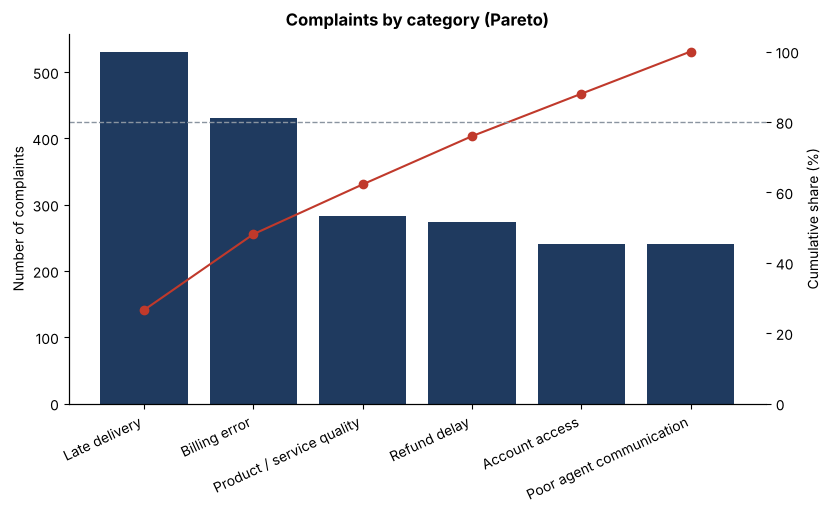

In [4]:
counts = df['category'].value_counts()
cum = counts.cumsum() / counts.sum() * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(counts.index, counts.values, color=BLUE)
ax.set_ylabel('Number of complaints')
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=25, ha='right')
ax2 = ax.twinx()
ax2.plot(counts.index, cum.values, color=RED, marker='o')
ax2.set_ylim(0, 105)
ax2.set_ylabel('Cumulative share (%)')
ax2.spines['top'].set_visible(False)
ax2.axhline(80, color=GREY, ls='--', lw=1)
ax.set_title('Complaints by category (Pareto)', fontweight='bold')
plt.savefig('charts/complaints_pareto.png', dpi=130, bbox_inches='tight')
plt.show()

## 4. Where do customers wait longest?

In [5]:
wait = (df.groupby('category')['resolution_days']
          .agg(complaints='size', median_days='median', p90_days=lambda s: s.quantile(0.9))
          .round(1).sort_values('median_days', ascending=False))
wait

,complaints,median_days,p90_days
category,,,
Refund delay,274,4.6,10.3
Product / service quality,283,3.9,8.6
Late delivery,531,3.0,5.7
Billing error,431,2.0,3.9
Poor agent communication,240,1.5,3.5
Account access,241,1.0,2.0


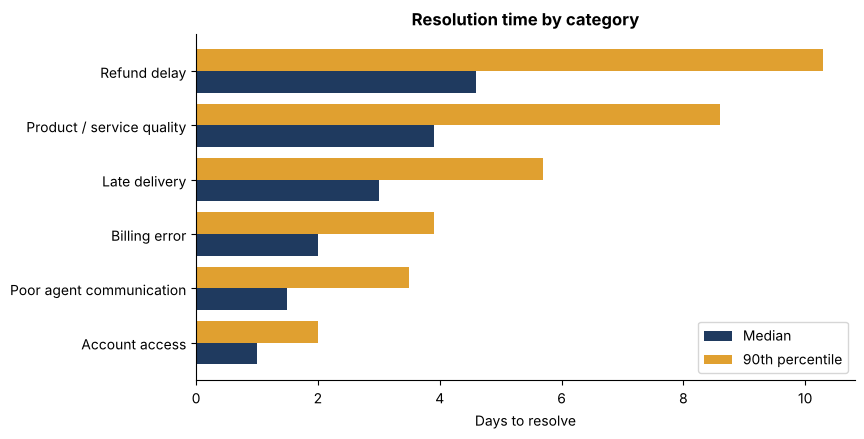

In [6]:
order = wait.sort_values('median_days').index
fig, ax = plt.subplots(figsize=(8.5, 4.5))
y = np.arange(len(order))
ax.barh(y - 0.2, wait.loc[order, 'median_days'], height=0.4, color=BLUE, label='Median')
ax.barh(y + 0.2, wait.loc[order, 'p90_days'], height=0.4, color=AMBER, label='90th percentile')
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel('Days to resolve')
ax.set_title('Resolution time by category', fontweight='bold')
ax.legend()
plt.savefig('charts/resolution_time_by_category.png', dpi=130, bbox_inches='tight')
plt.show()

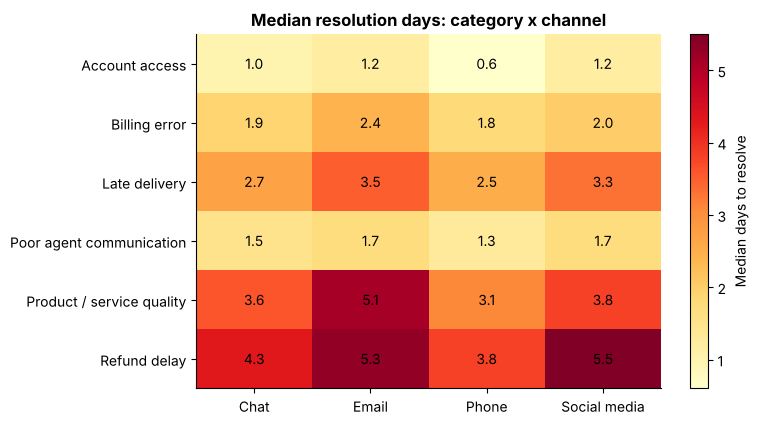

In [7]:
heat = df.pivot_table(index='category', columns='channel', values='resolution_days', aggfunc='median').round(1)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(heat.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat.values[i, j]:.1f}', ha='center', va='center', fontsize=10)
fig.colorbar(im, label='Median days to resolve')
ax.set_title('Median resolution days: category x channel', fontweight='bold')
plt.savefig('charts/resolution_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Effect of waiting time on satisfaction and repeat contacts

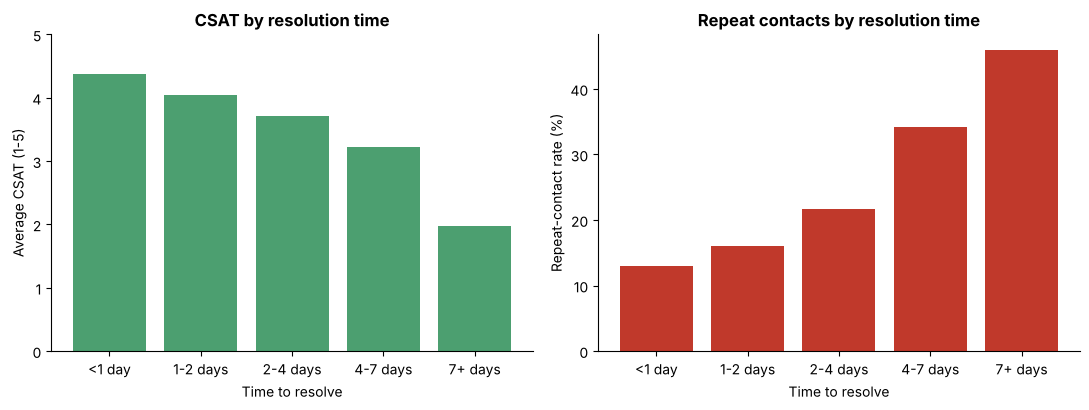

In [8]:
bins = pd.cut(df['resolution_days'], [0, 1, 2, 4, 7, 31], labels=['<1 day', '1-2 days', '2-4 days', '4-7 days', '7+ days'])
by_wait = df.groupby(bins, observed=True).agg(csat=('csat', 'mean'), repeat_rate=('repeat_contact', 'mean'), n=('csat', 'size'))
by_wait['repeat_rate'] = by_wait['repeat_rate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(by_wait.index.astype(str), by_wait['csat'], color=GREEN)
axes[0].set_ylim(0, 5)
axes[0].set_ylabel('Average CSAT (1-5)')
axes[0].set_title('CSAT by resolution time', fontweight='bold')
axes[1].bar(by_wait.index.astype(str), by_wait['repeat_rate'], color=RED)
axes[1].set_ylabel('Repeat-contact rate (%)')
axes[1].set_title('Repeat contacts by resolution time', fontweight='bold')
for a in axes:
    a.set_xlabel('Time to resolve')
plt.tight_layout()
plt.savefig('charts/csat_repeat_by_wait.png', dpi=130, bbox_inches='tight')
plt.show()

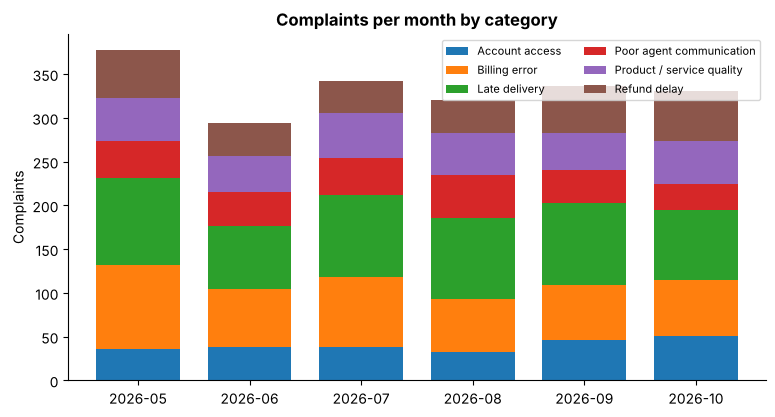

In [9]:
monthly = df.groupby(['month', 'category']).size().unstack(fill_value=0)
ax = monthly.plot(kind='bar', stacked=True, figsize=(9, 4.5), width=0.75)
ax.set_title('Complaints per month by category', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Complaints')
plt.xticks(rotation=0)
plt.legend(fontsize=8, ncol=2)
plt.savefig('charts/complaints_monthly.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. Findings and recommendations for root-cause analysis

The text below is generated from the data above, so it updates if the data changes.

In [10]:
repeat_by_cat = (df.groupby('category')['repeat_contact'].mean() * 100).round(1).sort_values(ascending=False)
top2 = counts.head(2)
slow2 = wait.head(2)
slowest_share = counts[top2.index].sum() / counts.sum() * 100

print('FINDINGS')
print(f"1. {top2.index[0]} and {top2.index[1]} are the two most common complaints, together {slowest_share:.0f}% of all complaints.")
print(f"2. Customers wait longest for {slow2.index[0]} (median {slow2['median_days'].iloc[0]} days) and {slow2.index[1]} (median {slow2['median_days'].iloc[1]} days).")
print(f"3. Complaints resolved in under 1 day score CSAT {by_wait['csat'].iloc[0]:.1f}, against {by_wait['csat'].iloc[-1]:.1f} when they take over 7 days.")
print(f"4. {repeat_by_cat.index[0]} has the highest repeat-contact rate ({repeat_by_cat.iloc[0]}%).")
print()
print('RECOMMENDATIONS')
print(f"- Review the {top2.index[0].lower()} process end to end with the operations team to find the root cause behind the volume.")
print(f"- Set a target and a tracking owner for {slow2.index[0].lower()} cases, since long waits drive lower CSAT and more repeat contacts.")
print(f"- Add a proactive status update for {repeat_by_cat.index[0].lower()} cases so customers do not need to chase.")
print("- Re-run this analysis monthly and compare against the targets above.")

FINDINGS
1. Late delivery and Billing error are the two most common complaints, together 48% of all complaints.
2. Customers wait longest for Refund delay (median 4.6 days) and Product / service quality (median 3.9 days).
3. Complaints resolved in under 1 day score CSAT 4.4, against 2.0 when they take over 7 days.
4. Product / service quality has the highest repeat-contact rate (33.9%).

RECOMMENDATIONS
- Review the late delivery process end to end with the operations team to find the root cause behind the volume.
- Set a target and a tracking owner for refund delay cases, since long waits drive lower CSAT and more repeat contacts.
- Add a proactive status update for product / service quality cases so customers do not need to chase.
- Re-run this analysis monthly and compare against the targets above.
